# 04 · Restock prediction

Goal: tell the admin **which shoes to restock, how many, and in which UK sizes**, and which ones are **overstocked**.

- **Groups:** shoe model (`products.name`) × size band: **S** = UK 3.0–5.5, **M** = UK 6.0–8.5, **L** = UK 9.0–12.0 → 22 models × 3 = **66 groups**.
  The report can also roll up by brand or category.
- **Question each Monday:** how many pairs will this group sell in the **next 14 days**? Will it sell out?
- **Code:** `ml-service/restock/` (`data.py`, `models.py`, `evaluation.py`, `report.py`).

### Censored demand (why we only train on groups with stock ≥ 2)
We only see **sales**, not **demand**. A group with 0 pairs sells 0, even if ten people wanted it; a group with 1 pair sells at most 1.
So for low-stock groups, sales *understate* demand (the demand is "censored" by stock). If a model learned from those weeks,
it would learn "this model doesn't sell" when the truth is "we had nothing to sell".
To reduce this, models are **trained only on snapshots where the group started with at least 2 pairs**, and when predicting,
the stock input is set to at least 2, so the forecast means **"demand if pairs were available"**.
This doesn't remove the problem completely: past sales features (sold in the last 28 days, etc.) are still lower after a sell-out.

In [1]:
import json
import sys
import warnings
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_DIR))
from restock.data import FEATURES, HORIZON, MIN_TRAIN_STOCK, NUMERIC_FEATURES, CATEGORICAL_FEATURES, build_snapshots, load_restock_data, snapshot_dates  # noqa: E402
from restock.evaluation import backtest, metrics, with_censoring_correction  # noqa: E402
from restock.models import MovingAverage, PoissonModel, RandomForestModel, UPPER_QUANTILE, XGBoostModel, predict_demand  # noqa: E402
from restock.report import RESTOCK_CONFIG, build_restock_report, in_stock_demand, size_plan  # noqa: E402

FIG_DIR, REPORT_DIR, MODEL_DIR = ML_DIR / "reports" / "figures", ML_DIR / "reports", ML_DIR / "models"
COLORS = {"Moving average": "#78716c", "Poisson regression": "#1d4ed8", "Random forest": "#d97706", "XGBoost (Poisson)": "#047857",
          "Random forest + censored-demand correction": "#b45309"}
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print("saved", name)

## 1. Rebuilding the stock history
Each product is one pair. A pair is **in stock** from its `created_at` until it is **sold** (the first order containing it that isn't
cancelled or failed) or **hidden** (`updated_at` when status = hidden). Pairs in cancelled or failed orders go back on sale.
All days are Malaysian days (UTC+8); "stock on day d" means pairs in stock at the start of that day.

The check below compares the rebuilt history with the database today.

66 groups · data until 07 Nov 2026
Rebuilt stock at the start of 08 Nov 2026: 217 pairs · products with status 'available' now: 217
Units sold (rebuilt): 2,559 · products with status 'sold': 2,559
Groups where they differ: 0


saved 05_stock_and_sales.png


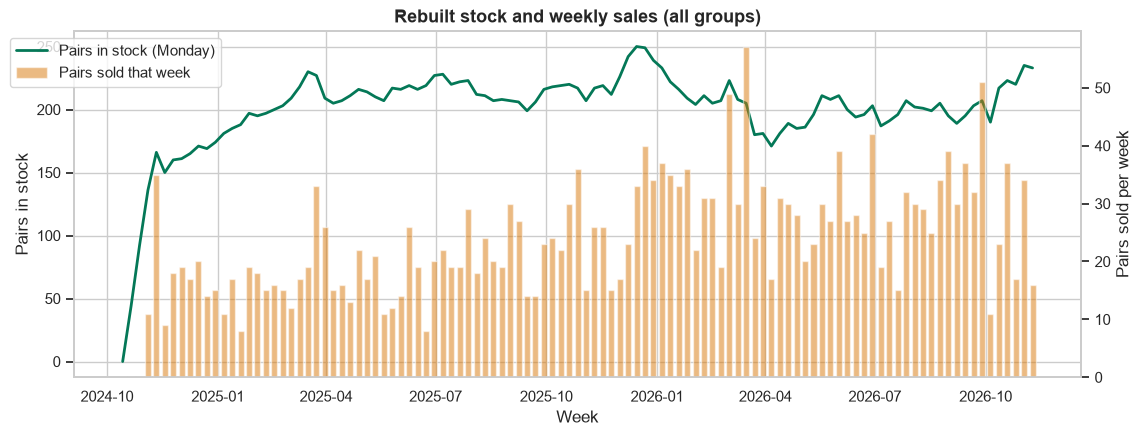

In [2]:
data = load_restock_data()
as_of = pd.Timestamp("2026-11-08")
print(f"{len(data.groups)} groups · data until {data.last_day:%d %b %Y}")
print(f"Rebuilt stock at the start of {as_of:%d %b %Y}: {int(data.stock.loc[as_of].sum())} pairs · products with status 'available' now: {int((data.products['status'] == 'available').sum())}")
print(f"Units sold (rebuilt): {int(data.sales.sum().sum()):,} · products with status 'sold': {int((data.products['status'] == 'sold').sum()):,}")
check = pd.DataFrame({"rebuilt stock": data.stock.loc[as_of],
                      "available now": data.products[data.products["status"] == "available"].groupby("group").size().reindex(data.groups.index, fill_value=0)})
print("Groups where they differ:", int((check["rebuilt stock"] != check["available now"]).sum()))

weekly_stock = data.stock.loc[:data.last_day].sum(axis=1).resample("W-MON").first()
weekly_sales = data.sales.loc[:data.last_day].sum(axis=1).resample("W-MON").sum()
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.plot(weekly_stock.index, weekly_stock.values, color="#047857", lw=2, label="Pairs in stock (Monday)")
ax2 = ax1.twinx()
ax2.bar(weekly_sales.index, weekly_sales.values, width=5, color="#d97706", alpha=0.5, label="Pairs sold that week")
ax1.set(title="Rebuilt stock and weekly sales (all groups)", xlabel="Week", ylabel="Pairs in stock")
ax2.set_ylabel("Pairs sold per week")
ax2.grid(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88))
save(fig, "05_stock_and_sales.png")
plt.show()

**Finding:** The rebuilt history matches the database exactly: 217 pairs in stock at the start of 8 Nov 2026 (= products now 'available', with 0 groups different) and 2,559 units sold (= products 'sold'). Every sold pair is in exactly one valid order; 180 pairs had an earlier cancelled or failed order and correctly went back on sale. Stock across all groups usually sits between about 150 and 250 pairs, refilled weekly.

## 2. Weekly snapshots
Every Monday, for every group, we record what was known **before** that day:

| Feature | Meaning |
|---|---|
| stock | pairs in stock at the start of Monday |
| sold_7 / 14 / 28 / 56 | pairs sold in the last 7, 14, 28, 56 days |
| days_since_last_sale | days since the group last sold (365 if never) |
| trend_28 | sold in the last 28 days minus the 28 days before |
| avg_price, avg_price_ratio | average listed price of the pairs in stock, and price ÷ retail price (all listed pairs if none in stock) |
| views_14 | product page views in the last 14 days |
| next14_major_event_days, next14_payday_days | major event days (11.11, 12.12, Black Friday, pre-Raya, Raya closure) and payday days in the **next** 14 days, from the calendar |
| brand, category, size_band | what the group is |

**Target:** pairs sold in the next 14 days. Snapshots start 56 days after the first sale (so every window is complete) and end on the last Monday whose
14 days are fully in the data.

In [3]:
dates = snapshot_dates(data)
snapshots = build_snapshots(data, dates)
print(f"{len(dates)} Mondays ({dates[0]:%d %b %Y} – {dates[-1]:%d %b %Y}) × {len(data.groups)} groups = {len(snapshots):,} snapshots")
low = snapshots["stock"] < MIN_TRAIN_STOCK
print(f"Snapshots with stock < {MIN_TRAIN_STOCK}: {low.mean():.0%} (left out of training)")
censor = snapshots.assign(stock_level=pd.cut(snapshots["stock"], [-1, 0, 1, 2, 4, 100], labels=["0", "1", "2", "3–4", "5+"]))
display(censor.groupby("stock_level", observed=True).agg(snapshots=("target", "size"), avg_sold_next_14=("target", "mean"),
                                                         avg_sold_last_28=("sold_28", "mean"), sold_out_share=("target", lambda s: np.nan))
        .drop(columns="sold_out_share").round(2))
snapshots[FEATURES + ["target"]].describe().T[["mean", "50%", "max"]].round(2)

95 Mondays (30 Dec 2024 – 19 Oct 2026) × 66 groups = 6,270 snapshots
Snapshots with stock < 2: 25% (left out of training)


,snapshots,avg_sold_next_14,avg_sold_last_28
stock_level,,,
0,495,0.110,1.640
1,1070,0.370,1.450
2,1145,0.640,1.550
3–4,1974,0.860,1.460
5+,1586,1.160,1.450


,mean,50%,max
stock,3.210,3.000,14.000
sold_7,0.370,0.000,4.000
sold_14,0.740,0.000,7.000
sold_28,1.490,1.000,11.000
sold_56,2.930,2.000,19.000
days_since_last_sale,36.350,17.000,365.000
trend_28,0.040,0.000,10.000
avg_price,192.290,180.830,562.500
avg_price_ratio,0.370,0.340,1.230
views_14,2.790,2.000,22.000


**Finding:** There are 6,270 snapshots (95 Mondays × 66 groups); a typical group has 3 pairs and sells 0.75 pairs in 14 days. **Censoring is clearly visible**: groups starting the week with 0 pairs "sold" 0.11 in the next 14 days, groups with 1 pair 0.37 and groups with 5+ pairs 1.16, although all of them had sold about 1.5 pairs in the previous 28 days. Most of that difference is missing stock, not missing demand, which is why the 25% of snapshots with fewer than 2 pairs are left out of training.

## 3. The four models, in simple words

| Model | How it predicts the next 14 days | Why it's here |
|---|---|---|
| **Moving average** | Half of what the group sold in the last 28 days. | The **baseline** a model has to beat. |
| **Poisson regression** | A formula: log(demand) = a weighted sum of the features. Made for counts (0, 1, 2 … pairs). | Simple, explainable, and suited to small counts. |
| **Random forest** | 300 decision trees, each trained on a random sample of past weeks; the answer is their average. | Handles non-linear patterns and interactions; hard to overfit. |
| **XGBoost (Poisson)** | Many small trees built one after another, each fixing the previous ones' errors, with a count (Poisson) objective. | Usually the strongest on tabular data. |

Each model gives an **expected demand** and an **80% upper bound**: the 80th percentile of a Poisson distribution with that mean,
so demand should be at or below it 8 weeks in 10. The upper bound is what the restock quantity is based on.

## 4. Rolling-origin backtest (last 13 Mondays)
For each of the last 13 Mondays, every model is trained on earlier snapshots and predicts all 66 groups.
**No peeking:** a snapshot's target covers the 14 days after it, so a training snapshot must be at least 14 days older than the test Monday
(otherwise its target would include days of the test period). Training uses snapshots with stock ≥ 2 only.

**Metrics**
- **MAE / RMSE** (pairs): forecast error, on test groups with stock ≥ 2 (where sales ≈ demand).
- **Sell-out detection**, on test groups with stock ≥ 1: a group *sells out* if it sold at least as many pairs as it had (sales ≥ stock).
  The model *predicts* a sell-out if its expected demand ≥ stock (the same rule as a HIGH/MEDIUM risk flag in the report).
  **Precision** = of the predicted sell-outs, how many really sold out; **recall** = of the real sell-outs, how many were predicted; **F1** combines both.
- For information: F1 when the 80% upper bound is used instead, and how often demand stayed below the upper bound.

In [4]:
test_dates = dates[-13:]
print(f"Test Mondays: {test_dates[0]:%d %b} – {test_dates[-1]:%d %b %Y}")
models = [MovingAverage(), PoissonModel(), RandomForestModel(), XGBoostModel()]
results = backtest(models, snapshots, test_dates)
base_table = metrics(results)
table = base_table
table.style.format({"MAE (units)": "{:.3f}", "RMSE (units)": "{:.3f}", "bias (units)": "{:+.3f}", "80% upper coverage (%)": "{:.0f}%",
                    "sell-out precision": "{:.2f}", "sell-out recall": "{:.2f}", "sell-out F1": "{:.3f}", "F1 (upper-bound rule)": "{:.3f}",
                    "recall (upper-bound rule)": "{:.2f}"}).hide(axis="index")

Test Mondays: 27 Jul – 19 Oct 2026


model,MAE (units),RMSE (units),bias (units),80% upper coverage (%),sell-out precision,sell-out recall,sell-out F1,F1 (upper-bound rule),recall (upper-bound rule),sell-outs (actual),group-weeks scored
Moving average,0.849,1.175,-0.188,77%,0.59,0.49,0.533,0.537,0.70,140,773
Random forest,0.740,0.950,-0.077,85%,0.71,0.41,0.518,0.611,0.81,140,773
Poisson regression,0.803,1.064,-0.090,85%,0.84,0.35,0.495,0.641,0.82,140,773
XGBoost (Poisson),0.739,0.954,-0.133,86%,0.74,0.33,0.455,0.628,0.85,140,773


**Finding:** The learned models are more **accurate**: Random forest and XGBoost have an MAE of 0.74 pairs vs 0.85 for the moving average (−13%), and their 80% upper bound holds 85–86% of the time (the moving average's only 77%). On **sell-out detection with the point forecast** the moving average has the highest F1 (0.533), just ahead of Random forest (0.518). The learned models are cautious: high precision (0.71–0.84, so when they say a group will sell out it usually does) but low recall (0.33–0.41, so they miss most sell-outs). Their expected demand is usually below 1 pair, so a 1-pair group is rarely flagged. When the **80% upper bound** is used for the sell-out call instead, all learned models beat the baseline clearly (F1 0.61–0.64 vs 0.54).

### Is the F1 difference real?
F1 rests on about 140 sell-outs in 13 weeks, so small gaps can be luck. The test weeks are resampled 2,000 times (bootstrap)
to see how often each model would come out on top.

In [5]:
rng = np.random.default_rng(0)
weeks = results["date"].unique()
leader = base_table.loc[0, "model"]
wins, f1_samples = {m: 0 for m in base_table["model"]}, {m: [] for m in base_table["model"]}
gaps = {m: [] for m in base_table["model"] if m != leader}
for _ in range(2000):
    sample = rng.choice(weeks, size=len(weeks), replace=True)
    boot = pd.concat([results[results["date"] == w] for w in sample])
    scores = metrics(boot).set_index("model")["sell-out F1"]
    wins[scores.idxmax()] += 1
    for m, v in scores.items():
        f1_samples[m].append(v)
    for m in gaps:  # paired: same resampled weeks for both models
        gaps[m].append(scores[leader] - scores[m])
boot_table = pd.DataFrame({"F1": base_table.set_index("model")["sell-out F1"],
                           "F1 90% interval": {m: f"{np.percentile(v, 5):.2f} – {np.percentile(v, 95):.2f}" for m, v in f1_samples.items()},
                           "share of resamples where it is best": {m: wins[m] / 2000 for m in wins}})
display(boot_table.style.format({"F1": "{:.3f}", "share of resamples where it is best": "{:.0%}"}))

tie_test = pd.DataFrame({m: {"F1 gap to " + leader: base_table.set_index("model").loc[leader, "sell-out F1"] - base_table.set_index("model").loc[m, "sell-out F1"],
                             "gap 90% interval (paired)": f"{np.percentile(g, 5):+.3f} … {np.percentile(g, 95):+.3f}",
                             "tied with the leader": np.percentile(g, 5) <= 0,
                             "MAE (units)": base_table.set_index("model").loc[m, "MAE (units)"]} for m, g in gaps.items()}).T
tie_test.style.format({"F1 gap to " + leader: "{:.3f}", "MAE (units)": "{:.4f}"})

,F1,F1 90% interval,share of resamples where it is best
Moving average,0.533,0.47 – 0.59,63%
Random forest,0.518,0.46 – 0.57,34%
Poisson regression,0.495,0.44 – 0.55,4%
XGBoost (Poisson),0.455,0.39 – 0.52,0%


,F1 gap to Moving average,gap 90% interval (paired),tied with the leader,MAE (units)
Random forest,0.015,-0.065 … +0.093,True,0.7396
Poisson regression,0.038,-0.039 … +0.114,True,0.8027
XGBoost (Poisson),0.078,-0.007 … +0.156,True,0.7385


**Finding:** The F1 gap between the moving average and the Random forest is **not significant**. Their 90% intervals overlap almost completely (0.47–0.59 vs 0.46–0.57), and in the **paired** test (same resampled weeks for both) the gap's interval is −0.065 … +0.093, which includes 0. The moving average is best in only 63% of resamples. The paired test also counts Poisson regression (−0.039 … +0.114) and XGBoost as tied, though XGBoost only just (−0.007 … +0.156).

## 5. Choosing the model: F1 first, MAE as tiebreak
**Why F1 matters more than MAE for the admin.** The admin doesn't act on "0.8 pairs vs 1.1 pairs"; they act on a yes/no question:
*will this group run out before the next bale arrives?* A missed sell-out (low recall) means empty shelves and lost sales of the most wanted
models; a false alarm (low precision) means buying stock that sits. F1 balances those two kinds of mistakes, while MAE rewards being close
on average, which is dominated by the many quiet groups that sell 0–1 pairs. So the model is chosen by **sell-out F1**, with MAE only to break ties.

**Decision: a statistical tie, so the MAE tiebreak decides.** The moving average has the highest F1 (0.533), but the random forest (0.518) is not
significantly worse: the paired bootstrap interval of the gap includes 0, and the moving average is best in only about 63% of resamples. A gap that
is within noise is treated as a **tie between the two front-runners**, and the rule's tiebreak (lower MAE) then picks the **random forest**
(MAE 0.740 vs 0.849, 13% lower). The moving average stays in the results table.

For transparency: the paired test above also counts Poisson regression and XGBoost as tied with the leader (XGBoost only just, with the
interval's lower end at about −0.007). Applied to all four models, the tiebreak would pick XGBoost, whose MAE is 0.001 pairs lower than the random forest's.
That difference is negligible, and XGBoost has the lowest F1 of all (0.455), so the decision compares the two front-runners.

In [6]:
best_name = "Random forest"
best_proto = {m.name: m for m in models}[best_name]
row = base_table.set_index("model")
print(f"F1 leader: {leader} ({row.loc[leader, 'sell-out F1']:.3f}) · tied front-runner: {best_name} ({row.loc[best_name, 'sell-out F1']:.3f})")
print(f"MAE tiebreak: {best_name} {row.loc[best_name, 'MAE (units)']:.3f} vs {leader} {row.loc[leader, 'MAE (units)']:.3f} -> chosen: {best_name}")

F1 leader: Moving average (0.533) · tied front-runner: Random forest (0.518)
MAE tiebreak: Random forest 0.740 vs Moving average 0.849 -> chosen: Random forest


**Finding:** Because the F1 gap between the two front-runners is within noise, it is treated as a **tie**, and the rule's tiebreak (lower MAE) picks the **Random forest**: 0.740 vs 0.849 pairs, 13% lower. The moving average stays in the results table. Applied strictly to all four models, the tiebreak would pick XGBoost by 0.001 pairs of MAE. That difference is negligible, and XGBoost has the lowest F1 (0.455), so the decision is between the two front-runners.

## 6. Censored-demand correction
The model predicts demand "as if stock were available", but its inputs still carry the censoring: a group that sat empty for weeks has few recent sales.
So for groups with **fewer than 2 pairs**, a second estimate is made from the days the group actually **had stock**:

`in-stock demand rate = pairs sold in the last 180 days ÷ days in that period with at least 1 pair in stock`

(skipped if the group had stock on fewer than 14 of those days). The 14-day demand is then **max(model prediction, in-stock rate × 14)**,
and a **demand source** column shows which one was used. Groups with 2+ pairs keep the model's prediction.

The correction is backtested on the same 13 Mondays, using only data before each Monday. MAE is scored on groups with ≥ 2 pairs, which the correction
doesn't touch, so it can only change the sell-out scores (through groups with 1 pair). Groups with 0 pairs can't be scored at all: they can't sell out.

In [7]:
results = with_censoring_correction(results, data, best_name)
table = metrics(results)
EVALUATED_AT = datetime.now(timezone.utc)  # when these test figures were calculated (saved with them below)
evaluated_on = pd.Timestamp(EVALUATED_AT).tz_convert("Asia/Kuala_Lumpur").strftime("%Y-%m-%d")
table.round(3).assign(evaluated_on=evaluated_on).to_csv(REPORT_DIR / "restock_model_comparison.csv", index=False)
print("saved reports/restock_model_comparison.csv")
corrected = results[results["model"] == f"{best_name} + censored-demand correction"]
print(f"Group-weeks where the in-stock rate replaced the model: {(corrected['demand_source'] == 'in-stock rate').sum()} of {len(corrected)} "
      f"({(corrected['stock'] < 2).sum()} had fewer than 2 pairs)")
table.style.format({"MAE (units)": "{:.3f}", "RMSE (units)": "{:.3f}", "bias (units)": "{:+.3f}", "80% upper coverage (%)": "{:.0f}%",
                    "sell-out precision": "{:.2f}", "sell-out recall": "{:.2f}", "sell-out F1": "{:.3f}", "F1 (upper-bound rule)": "{:.3f}",
                    "recall (upper-bound rule)": "{:.2f}"}).hide(axis="index")

saved reports/restock_model_comparison.csv
Group-weeks where the in-stock rate replaced the model: 177 of 858 (221 had fewer than 2 pairs)


model,MAE (units),RMSE (units),bias (units),80% upper coverage (%),sell-out precision,sell-out recall,sell-out F1,F1 (upper-bound rule),recall (upper-bound rule),sell-outs (actual),group-weeks scored
Random forest + censored-demand correction,0.740,0.950,-0.077,85%,0.67,0.56,0.612,0.624,0.84,140,773
Moving average,0.849,1.175,-0.188,77%,0.59,0.49,0.533,0.537,0.70,140,773
Random forest,0.740,0.950,-0.077,85%,0.71,0.41,0.518,0.611,0.81,140,773
Poisson regression,0.803,1.064,-0.090,85%,0.84,0.35,0.495,0.641,0.82,140,773
XGBoost (Poisson),0.739,0.954,-0.133,86%,0.74,0.33,0.455,0.628,0.85,140,773


**Finding:** The correction changed the demand of 177 of 858 group-weeks (out of the 221 with fewer than 2 pairs). It lifts the Random forest's sell-out **recall from 0.41 to 0.56** at a small cost in precision (0.71 → 0.67), so **F1 rises from 0.518 to 0.612**, the best point-forecast F1 of all versions and clearly above the moving average (0.533). MAE, RMSE and the upper-bound coverage are unchanged, as expected: they are scored on groups with 2+ pairs, which the correction doesn't touch. So the correction does what it was meant to do: it recovers demand the model couldn't see in nearly empty groups.

saved 05_mae_by_model.png


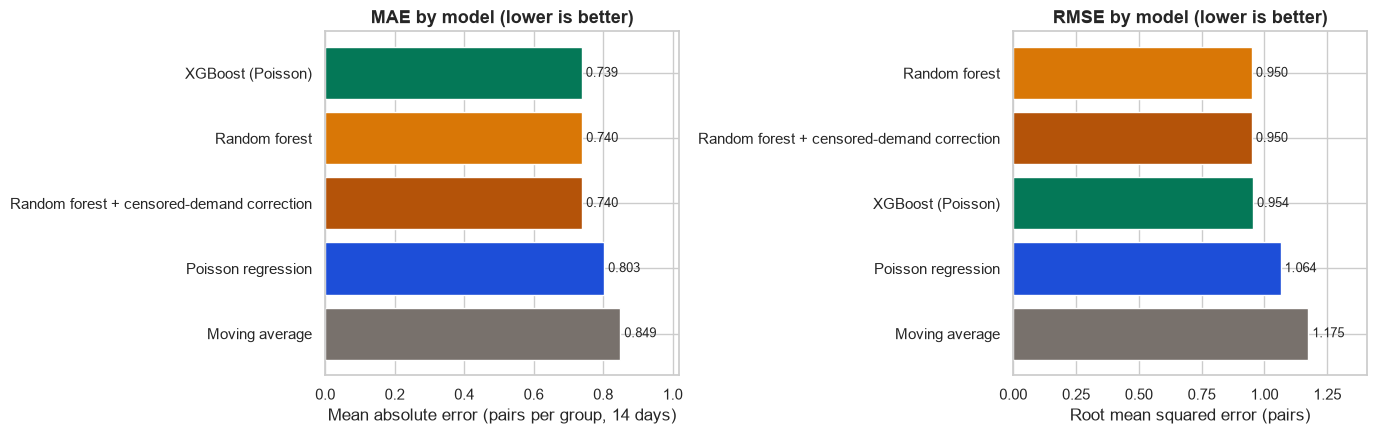

saved 05_f1_by_model.png


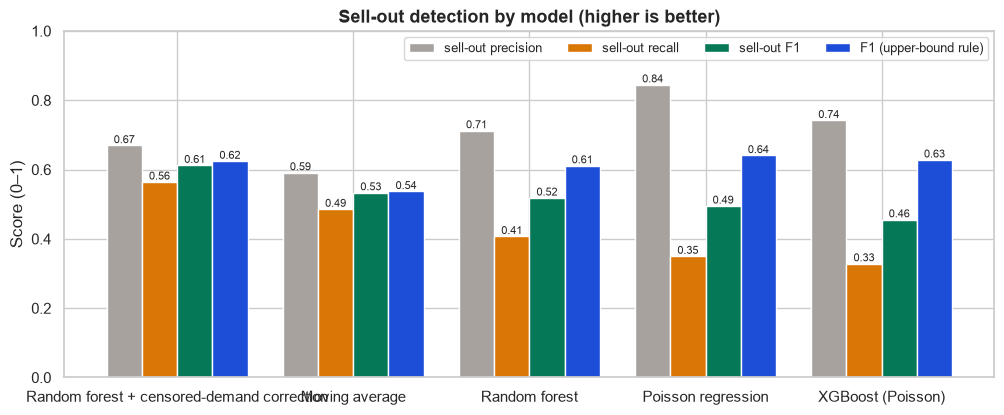

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = table.sort_values("MAE (units)", ascending=False)
axes[0].barh(order["model"], order["MAE (units)"], color=[COLORS[m] for m in order["model"]])
for i, v in enumerate(order["MAE (units)"]):
    axes[0].text(v, i, f" {v:.3f}", va="center", fontsize=9)
axes[0].set(title="MAE by model (lower is better)", xlabel="Mean absolute error (pairs per group, 14 days)")
axes[0].set_xlim(0, order["MAE (units)"].max() * 1.2)
order = table.sort_values("RMSE (units)", ascending=False)
axes[1].barh(order["model"], order["RMSE (units)"], color=[COLORS[m] for m in order["model"]])
for i, v in enumerate(order["RMSE (units)"]):
    axes[1].text(v, i, f" {v:.3f}", va="center", fontsize=9)
axes[1].set(title="RMSE by model (lower is better)", xlabel="Root mean squared error (pairs)")
axes[1].set_xlim(0, order["RMSE (units)"].max() * 1.2)
fig.tight_layout()
save(fig, "05_mae_by_model.png")
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(table))
for i, (metric, color) in enumerate([("sell-out precision", "#a8a29e"), ("sell-out recall", "#d97706"), ("sell-out F1", "#047857"), ("F1 (upper-bound rule)", "#1d4ed8")]):
    bars = ax.bar(x + (i - 1.5) * 0.2, table[metric], 0.2, color=color, label=metric)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, table["model"])
ax.set(title="Sell-out detection by model (higher is better)", ylabel="Score (0–1)", ylim=(0, 1))
ax.legend(ncol=4, fontsize=9, loc="upper right")
save(fig, "05_f1_by_model.png")
plt.show()

**Finding:** In the charts, the Random forest (and its corrected version) has the lowest MAE and RMSE, together with XGBoost. On sell-out detection the corrected Random forest has the best balance of precision and recall (F1 0.61). The uncorrected learned models trade recall for precision, and the moving average sits in between.

### Predicted vs actual (best model, test weeks)

saved 05_predicted_vs_actual.png


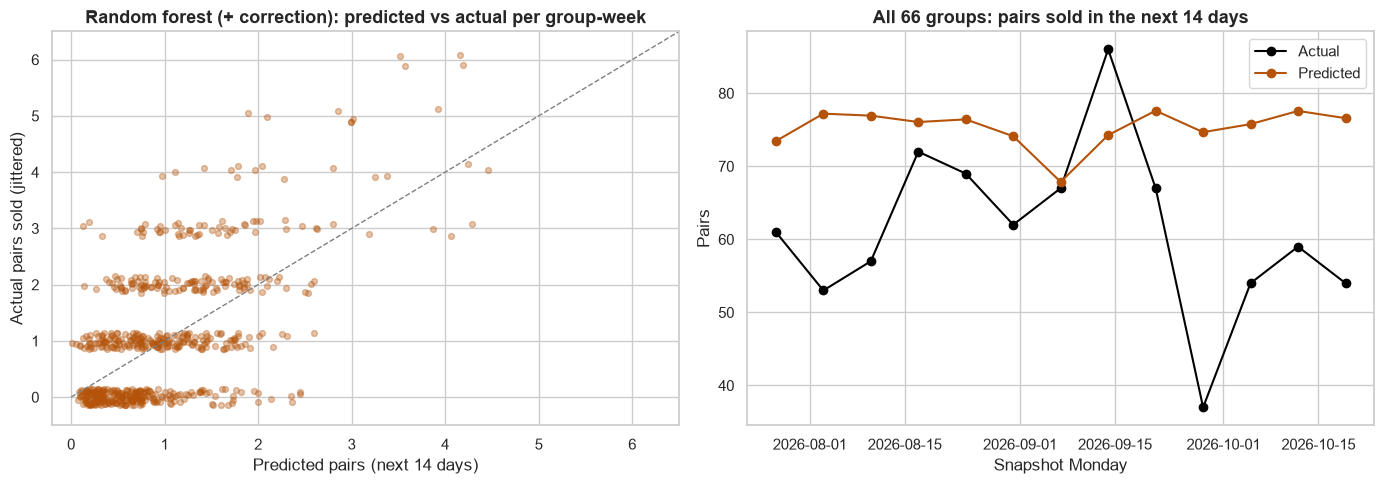

In [9]:
final_name = f"{best_name} + censored-demand correction"
best = results[results["model"] == final_name]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
demand = best[best["stock"] >= MIN_TRAIN_STOCK]
jitter = np.random.default_rng(1).uniform(-0.15, 0.15, len(demand))
axes[0].scatter(demand["yhat"], demand["target"] + jitter, alpha=0.35, s=18, color=COLORS[final_name])
lim = max(demand["yhat"].max(), demand["target"].max()) + 0.5
axes[0].plot([0, lim], [0, lim], color="grey", ls="--", lw=1)
axes[0].set(title=f"{best_name} (+ correction): predicted vs actual per group-week", xlabel="Predicted pairs (next 14 days)", ylabel="Actual pairs sold (jittered)", xlim=(-0.2, lim), ylim=(-0.5, lim))
weekly = best.groupby("date")[["target", "yhat"]].sum()
axes[1].plot(weekly.index, weekly["target"], marker="o", color="black", label="Actual")
axes[1].plot(weekly.index, weekly["yhat"], marker="o", color=COLORS[final_name], label="Predicted")
axes[1].set(title="All 66 groups: pairs sold in the next 14 days", xlabel="Snapshot Monday", ylabel="Pairs")
axes[1].legend()
fig.tight_layout()
save(fig, "05_predicted_vs_actual.png")
plt.show()

**Finding:** Per group and week the predictions are rough: actual sales of 0–6 pairs scatter widely around predictions of 0–4.5, because single pairs sell irregularly. Added up over all 66 groups, predicted demand (about 74–78 pairs per 14 days) is **above** actual sales in most weeks (37–86). That's expected: the prediction is demand *if pairs were available*, including the empty groups, while their actual sales are capped by stock. The gap is roughly the demand lost to empty shelves.

### Feature importance (random forest)

saved 05_feature_importance.png


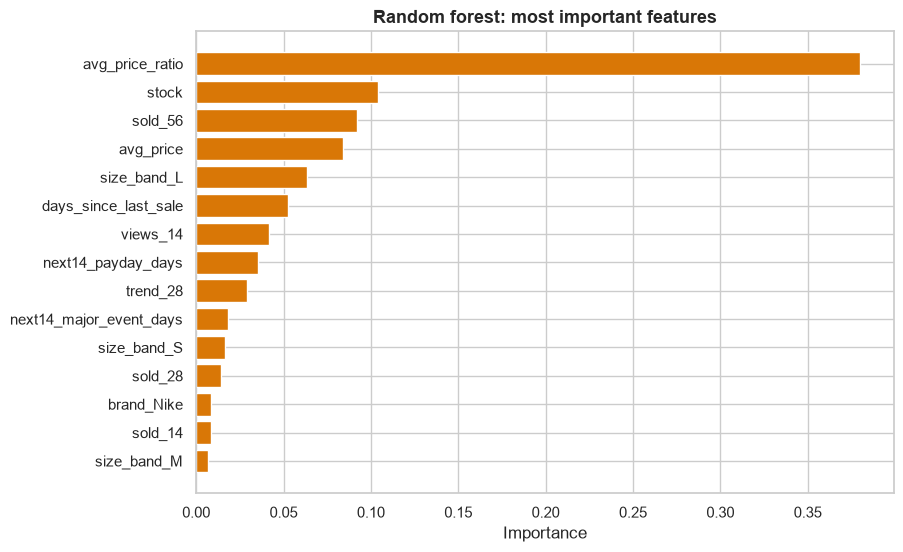

In [10]:
importance_name = best_name
proto = {m.name: m for m in models}[importance_name]
train_all = snapshots[snapshots["stock"] >= MIN_TRAIN_STOCK]
fitted_importance = type(proto)().fit(train_all[FEATURES], train_all["target"])
importance = fitted_importance.feature_importance().head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importance.index, importance.values, color=COLORS[importance_name])
ax.set(title=f"{importance_name}: most important features", xlabel="Importance" + (" (|coefficient| on scaled features)" if importance_name == "Poisson regression" else ""), ylabel="")
save(fig, "05_feature_importance.png")
plt.show()

**Finding:** For the Random forest (the best learned model, shown because the moving average has no features), **the price/retail ratio of the pairs in stock is by far the strongest signal** (importance about 0.38): groups priced well below retail sell faster, which matches notebook 01's finding that cheaper pairs sell quicker. Next come stock (about 0.10), sales in the last 56 days, the average price, the large size band (L, which sells less) and days since the last sale. Product views, payday days and the 28-day trend add a little; major events, brand and category matter least.

## 7. Final model and the restock report
The chosen model is retrained on **all** snapshots with stock ≥ 2 and saved to `models/restock_model.joblib` (+ JSON metadata).
`build_restock_report(as_of_date)` then gives, per group:

- **current stock**, **predicted demand** for the next 14 days (with the censored-demand correction and its **demand source**) and the **80% upper demand**;
- **days of cover** = stock ÷ daily demand;
- **risk**: HIGH (cover < 7 days), MEDIUM (7–14), LOW (> 14), OVERSTOCK (cover > 90 days and stock ≥ 3);
- **suggested restock** = max(0, ⌈80% upper demand⌉ − stock);
- **sizes to look for**: the suggested pairs split into exact UK sizes by each size's share of the last 180 days' sales
  (plus 0.5 per size, so unsold sizes still get a small share), minus pairs already in stock in that size.

All thresholds are in `RESTOCK_CONFIG` (in `restock/report.py`), so the admin can change them later.

In [11]:
final = type(best_proto)().fit(train_all[FEATURES], train_all["target"])
model_path = MODEL_DIR / "restock_model.joblib"
joblib.dump(final, model_path)
best_row = table.set_index("model").loc[final_name]
metadata = {
    "model_name": best_name,
    "model_class": f"restock.models.{type(final).__name__}",
    "target": "pairs sold per group in the next 14 days (group = products.name x size band S/M/L)",
    "size_bands": {"S": "UK 3.0-5.5", "M": "UK 6.0-8.5", "L": "UK 9.0-12.0"},
    "features": FEATURES,
    "training": f"snapshots (Mondays) with stock >= {MIN_TRAIN_STOCK}, {snapshots['date'].min():%Y-%m-%d} to {snapshots['date'].max():%Y-%m-%d}, {len(train_all)} rows",
    "censored_demand": "trained on stock >= 2 only; predictions clip the stock input to >= 2 (demand if pairs were available)",
    "upper_bound": f"{UPPER_QUANTILE:.0%} quantile of Poisson(predicted demand)",
    "trained_until": f"{data.last_day:%Y-%m-%d}",
    "selection": ("sell-out F1 first, MAE as tiebreak. The moving average had the highest F1 (0.533) but the random forest (0.518) is "
                  "statistically tied (paired bootstrap gap interval includes 0), so the MAE tiebreak picks the random forest (0.740 vs 0.849)."),
    "censored_demand_correction": {k: RESTOCK_CONFIG[k] for k in ["censor_stock_below", "in_stock_window_days", "min_in_stock_days"]}
                                  | {"rule": "groups with stock < 2: demand = max(model, sales in last 180 days / in-stock days x 14)"},
    "evaluation": {"test_mondays": [f"{d:%Y-%m-%d}" for d in test_dates], "metrics": {k: (round(float(v), 4) if isinstance(v, (int, float, np.floating, np.integer)) else v) for k, v in best_row.items()},
                   "all_models": table.round(4).to_dict(orient="records")},
    "report_config": RESTOCK_CONFIG,
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "evaluated_at": EVALUATED_AT.isoformat(timespec="seconds"),
    "evaluated_on_data_until": f"{data.last_day:%Y-%m-%d}",
    "versions": {p: version(p) for p in ["pandas", "numpy", "scikit-learn", "xgboost", "joblib"]},
    "load": "sys.path.insert(0, 'ml-service'); from restock.report import build_restock_report; build_restock_report('2026-11-08')",
}
(MODEL_DIR / "restock_model.json").write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")
assert np.allclose(joblib.load(model_path).predict(train_all[FEATURES].head(50))["yhat"], final.predict(train_all[FEATURES].head(50))["yhat"])
print(f"saved {model_path.name} + restock_model.json ({best_name}) · reload check passed")

saved restock_model.joblib + restock_model.json (Random forest) · reload check passed


In [12]:
report = build_restock_report("2026-11-08", data=data)
print("Restock report as of 8 Nov 2026 (data until 7 Nov) ·", ", ".join(f"{k}: {v}" for k, v in report["risk"].value_counts().reindex(["HIGH", "MEDIUM", "LOW", "OVERSTOCK"]).items()))
print(f"Total suggested restock: {int(report['suggested_restock_qty'].sum())} pairs across {(report['suggested_restock_qty'] > 0).sum()} groups")
columns = ["brand", "category", "stock", "model_demand_14d", "predicted_demand_14d", "demand_source", "upper_demand_14d", "days_of_cover", "risk", "suggested_restock_qty", "sizes_to_look_for"]
fmt = {"model_demand_14d": "{:.2f}", "predicted_demand_14d": "{:.2f}", "upper_demand_14d": "{:.0f}", "days_of_cover": "{:.1f}"}
print(f"Groups whose demand comes from the in-stock rate: {(report['demand_source'] == 'in-stock rate').sum()}")
high = report[report["risk"] == "HIGH"].sort_values(["suggested_restock_qty", "predicted_demand_14d"], ascending=False)
print(f"HIGH-risk groups ({len(high)}):")
display(high[columns].style.format(fmt))

Restock report as of 8 Nov 2026 (data until 7 Nov) · HIGH: 5, MEDIUM: 6, LOW: 40, OVERSTOCK: 15
Total suggested restock: 27 pairs across 13 groups
Groups whose demand comes from the in-stock rate: 9
HIGH-risk groups (5):


,brand,category,stock,model_demand_14d,predicted_demand_14d,demand_source,upper_demand_14d,days_of_cover,risk,suggested_restock_qty,sizes_to_look_for
group,,,,,,,,,,,
Adidas Samba OG · S,Adidas,Casual,0,2.95,4.24,in-stock rate,6,0.0,HIGH,6,"UK 4 x1 (22%), UK 3 x1 (20%), UK 5.5 x1 (20%), UK 5 x1 (17%), UK 4.5 x1 (13%), UK 3.5 x1 (8%)"
Adidas Samba OG · M,Adidas,Casual,0,3.19,4.21,in-stock rate,6,0.0,HIGH,6,"UK 8 x1 (24%), UK 7.5 x1 (20%), UK 7 x1 (15%), UK 8.5 x1 (15%), UK 6 x1 (13%), UK 6.5 x1 (13%)"
Converse Chuck 70 · S,Converse,Casual,0,1.62,2.06,in-stock rate,3,0.0,HIGH,3,"UK 5.5 x1 (30%), UK 4 x1 (20%), UK 4.5 x1 (20%)"
Nike Pegasus 40 · M,Nike,Running,0,0.71,1.29,in-stock rate,2,0.0,HIGH,2,"UK 8.5 x1 (23%), UK 6 x1 (17%)"
Clarks Tilden Cap Oxford · S,Clarks,Formal,0,0.61,0.78,in-stock rate,1,0.0,HIGH,1,UK 5 x1 (41%)


In [13]:
over = report[report["risk"] == "OVERSTOCK"].assign(excess=lambda r: r["stock"] - r["upper_demand_14d"]).sort_values(["days_of_cover", "stock"], ascending=False).head(5)
print(f"Top OVERSTOCK groups ({(report['risk'] == 'OVERSTOCK').sum()} in total), most days of cover first:")
display(over[[c for c in columns if c not in ("suggested_restock_qty", "sizes_to_look_for")] + ["excess"]].style.format({**fmt, "excess": "{:.0f}"}))
print("Roll-up by brand:")
display(build_restock_report("2026-11-08", level="brand", data=data).drop(columns="as_of").style.format({"predicted_demand_14d": "{:.2f}", "upper_demand_14d": "{:.0f}", "days_of_cover": "{:.1f}"}))

Top OVERSTOCK groups (15 in total), most days of cover first:


,brand,category,stock,model_demand_14d,predicted_demand_14d,demand_source,upper_demand_14d,days_of_cover,risk,excess
group,,,,,,,,,,
Puma RS-X · M,Puma,Sneakers,6,0.35,0.35,model,1,240.0,OVERSTOCK,5
Clarks Desert Boot · L,Clarks,Boots,4,0.24,0.24,model,1,233.3,OVERSTOCK,3
Dr. Martens 1461 Oxford · S,Dr. Martens,Formal,3,0.19,0.19,model,0,221.1,OVERSTOCK,3
Dr. Martens 1460 Boot · S,Dr. Martens,Boots,3,0.24,0.24,model,1,175.0,OVERSTOCK,2
Adidas Superstar · L,Adidas,Sneakers,4,0.36,0.36,model,1,155.6,OVERSTOCK,3


Roll-up by brand:


,stock,predicted_demand_14d,groups_corrected,sold_last_28d,groups,suggested_restock_qty,upper_demand_14d,days_of_cover,risk
brand,,,,,,,,,
Adidas,20,14.30,2,18,9,12,17,19.6,LOW
Nike,48,14.69,2,29,12,5,18,45.7,LOW
Converse,15,8.30,1,12,6,4,11,25.3,LOW
New Balance,18,7.78,2,12,6,3,10,32.4,LOW
Asics,21,9.75,1,15,6,1,12,30.2,LOW
Clarks,23,4.39,1,6,6,1,6,73.3,LOW
Puma,18,4.25,0,4,6,1,6,59.3,LOW
Birkenstock,15,4.59,0,7,3,0,6,45.8,LOW
Vans,11,3.63,0,4,3,0,5,42.4,LOW


In [14]:
example = high.index[0] if len(high) else report.index[0]
plan, text = size_plan(data, example, pd.Timestamp("2026-11-08"), report.loc[example, "upper_demand_14d"], report.loc[example, "suggested_restock_qty"])
print(f"Size split for {example}: {text or 'nothing to restock'}")
plan.style.format({"share": "{:.0%}", "gap": "{:.2f}"})

Size split for Adidas Samba OG · S: UK 4 x1 (22%), UK 3 x1 (20%), UK 5.5 x1 (20%), UK 5 x1 (17%), UK 4.5 x1 (13%), UK 3.5 x1 (8%)


,sold_180d,share,in_stock,gap,restock
size,,,,,
4.000000,9,22%,0,1.33,1
3.000000,8,20%,0,1.19,1
5.500000,8,20%,0,1.19,1
5.000000,7,17%,0,1.05,1
4.500000,5,13%,0,0.77,1
3.500000,3,8%,0,0.49,1


**Finding:** As of 8 Nov 2026: **5 HIGH**, 6 MEDIUM, 40 LOW and **15 OVERSTOCK** groups, with **27 pairs suggested** in total across 13 groups. For 9 groups the demand came from the in-stock rate. All 5 HIGH groups are empty, and the in-stock rate set the demand of all of them; this is exactly the correction's job. The list is led by the **Adidas Samba OG** (S: 6 pairs, M: 6 pairs, one of each size), then **Converse Chuck 70 S** (3), **Nike Pegasus 40 M** (2) and **Clarks Tilden Cap Oxford S** (1). With the Random forest, overstock is now led by groups with 3–6 pairs and very low predicted demand (Puma RS-X M, Clarks Desert Boot L, Dr. Martens 1461 Oxford S and 1460 Boot S, Adidas Superstar L: 150–240 days of cover). The moving average's overstock list (large sizes with no sales in 28 days) shrinks, because the Random forest still sees some demand there. Per brand, Adidas needs the most pairs (12), then Nike (5) and Converse (4).

## 8. Summary

- **Data:** the stock history rebuilt from listing, sale and hide dates matches the database exactly (217 pairs in stock, 2,559 sold). Weekly snapshots: 95 Mondays × 66 groups.
- **Censored demand is real:** empty groups "sell" about a tenth as much as well-stocked ones with the same recent sales. Models are trained on stock ≥ 2 and predict demand as if stock were available.
- **Model choice: Random forest.** The moving average had the highest F1 (0.533 vs 0.518), but the paired bootstrap shows a statistical tie, so the MAE tiebreak decides (0.740 vs 0.849 pairs). The moving average stays in the table for comparison.
- **Censored-demand correction:** for groups with fewer than 2 pairs, demand = max(model, sales per in-stock day over 180 days × 14). It raises the Random forest's sell-out F1 from 0.518 to **0.612** (recall 0.41 → 0.56) without changing MAE. That makes it the best version in the table, and it is what the report uses.
- **Report for 8 Nov 2026:** 5 HIGH groups, all empty and set by the in-stock rate, led by the Adidas Samba OG (6 pairs in S and 6 in M); 15 OVERSTOCK groups; 27 pairs suggested in total, each with exact UK sizes and a demand source.
- **Why F1:** the admin's decision is yes/no (will this group run out before the next bale?), so catching sell-outs without too many false alarms matters more than being a fraction of a pair closer on average.